<a href="https://colab.research.google.com/github/rons-12/fiap-tech-challenge-fase-2-wine-quality/blob/main/notebooks/01_wine_quality.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tech Challenge - Fase 02
## Case Wine Quality

## Contexto

A indústria vitivinícola possui grande relevância econômica e cultural em
diversos países. Tradicionalmente, a avaliação da qualidade de um vinho é realizada
por especialistas, por meio de análises sensoriais, que consideram aspectos como
aroma, sabor, acidez e equilíbrio. No entanto, esse processo pode ser subjetivo e
demandar tempo, além de depender da experiência dos avaliadores.

Com o avanço das técnicas de ciência de dados e aprendizado de máquina,
tornou-se possível utilizar dados físico-químicos obtidos durante a produção do vinho
para auxiliar na previsão da qualidade final do produto. Dessa forma, modelos
preditivos podem apoiar enólogos e produtores na tomada de decisão, permitindo
ajustes no processo produtivo e contribuindo para a padronização da qualidade.

## Proposta

O objetivo será desenvolver e treinar um modelo de classificação que seja capaz de prever a qualidade do vinho com base nas características físico-quimicas. A variável que utilizaremos será a "quality" onde transformaremos em uma classificação binária, tendo como alvo, Vinho de Alta Qualidade em notas >=7 e Vinho de Qualidade comum em notas <7. Vale ressaltar que na base utilizada há somente vinhos tintos da variedade portuguesa Vinho Verde. Portanto as conclusões valem para este recorte.


### Fonte: https://www.kaggle.com/datasets/yasserh/wine-quality-dataset

# Setup

In [2]:
RANDOM_STATE = 42

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
URL = "https://raw.githubusercontent.com/rons-12/fiap-tech-challenge-fase-2-wine-quality/main/data/WineQT.csv"
df = pd.read_csv(URL)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


In [6]:
df.shape

(1143, 13)

In [7]:
# Remoção da coluna "Id". Se trata apenas de um indice, sem caracteristicas a ser analisadas, e remoção das duplicatas.
df = df.drop(columns="Id")
n_antes = len(df)
df = df.drop_duplicates()
df = df.reset_index(drop=True)

In [8]:
print(f"Duplicatas removidas:{n_antes - len(df)} | Linhas finais: {len(df)}")

Duplicatas removidas:125 | Linhas finais: 1018


In [9]:
from sklearn.model_selection import train_test_split

In [10]:
# Removendo a coluna "Quality" da variável "x", pois ela é o nosso target. Como queremos (pelo
# enunciado) definir quais vinhos são "acima da média/alta qualidade" (nota >=7) e separa-los
# dos "vinhos comuns". Isso facilitará na compreensão do problema.

df["alta_qualidade"] = (df["quality"] >= 7).astype(int)
x = df.drop(columns=["quality", "alta_qualidade"])
y = df["alta_qualidade"]
y.value_counts(normalize=True)

,proportion
alta_qualidade,
0,0.865422
1,0.134578


In [11]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE)

In [12]:
x

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8
4,7.4,0.660,0.00,1.8,0.075,13.0,40.0,0.99780,3.51,0.56,9.4
...,...,...,...,...,...,...,...,...,...,...,...
1013,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0
1014,6.8,0.620,0.08,1.9,0.068,28.0,38.0,0.99651,3.42,0.82,9.5
1015,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5
1016,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2


In [13]:
y

,alta_qualidade
0,0
1,0
2,0
3,0
4,0
...,...
1013,0
1014,0
1015,0
1016,0


In [14]:
x.shape

(1018, 11)

In [15]:
y.shape

(1018,)

# Análise Exploratória - EDA

In [19]:
## Visão geral do Dataframe após as transformações anteriores.
## A fim de validar se não ficou nada fora do lugar

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1018 entries, 0 to 1017
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1018 non-null   float64
 1   volatile acidity      1018 non-null   float64
 2   citric acid           1018 non-null   float64
 3   residual sugar        1018 non-null   float64
 4   chlorides             1018 non-null   float64
 5   free sulfur dioxide   1018 non-null   float64
 6   total sulfur dioxide  1018 non-null   float64
 7   density               1018 non-null   float64
 8   pH                    1018 non-null   float64
 9   sulphates             1018 non-null   float64
 10  alcohol               1018 non-null   float64
 11  quality               1018 non-null   int64  
 12  alta_qualidade        1018 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 103.5 KB


In [20]:
## Nenhum dado ficou com valores negativos,
## logo o df não teve quebra nas trasnformações. Verificação necessária para
## garantir que nas etapas seguintes não tenhamos discrepancias ou valores
## incorretos nos resultados.

df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,alta_qualidade
count,1018.000000,1018.000000,1018.000000,1018.000000,1018.000000,1018.000000,1018.000000,1018.000000,1018.000000,1018.000000,1018.000000,1018.000000,1018.000000
mean,8.288507,0.533541,0.268802,2.524411,0.087187,15.648821,46.325639,0.996700,3.311503,0.656817,10.452456,5.641454,0.134578
std,1.741324,0.183167,0.196229,1.314850,0.048506,10.176525,33.123533,0.001916,0.157775,0.167542,1.095064,0.811744,0.341440
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000,0.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,21.000000,0.995572,3.210000,0.550000,9.500000,5.000000,0.000000
50%,7.900000,0.520000,0.250000,2.200000,0.079000,13.000000,38.000000,0.996665,3.310000,0.620000,10.200000,6.000000,0.000000
75%,9.100000,0.645000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997827,3.400000,0.720000,11.200000,6.000000,0.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,68.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000,1.000000


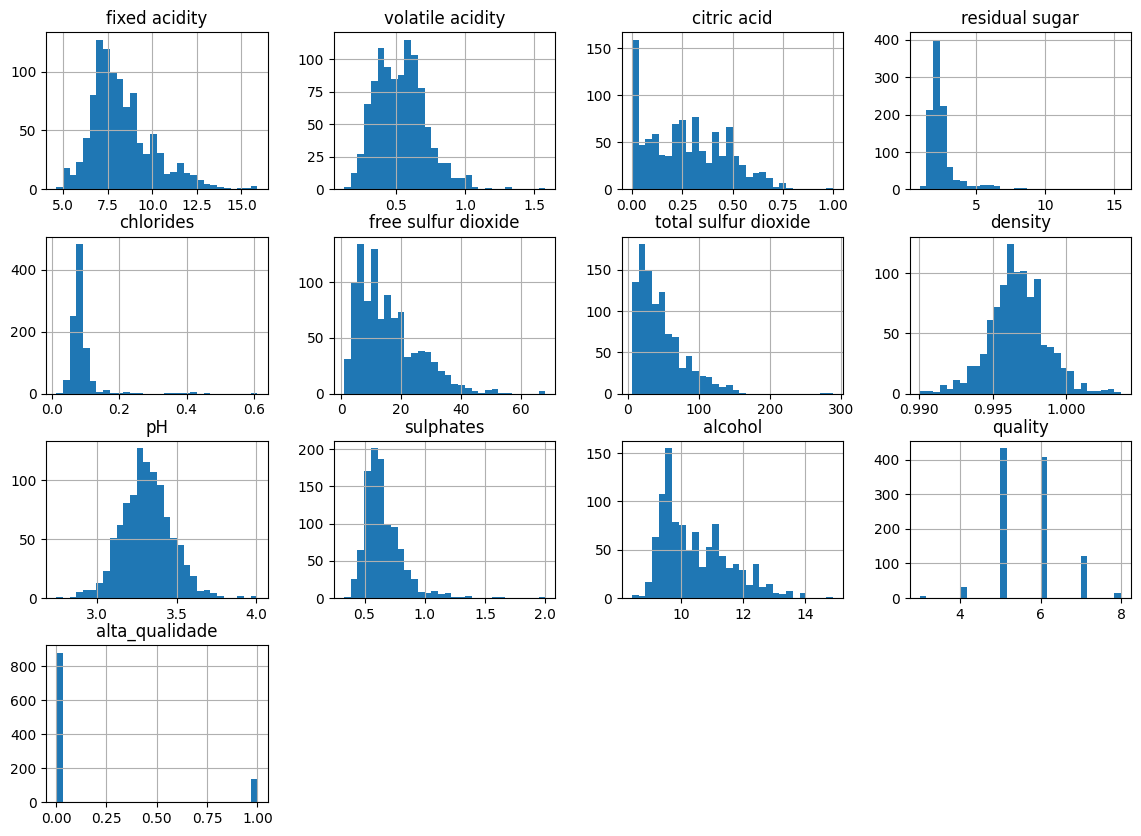

In [24]:
## Distribuição das variáveis

df.hist(bins=30, figsize=(14, 10))
plt.show()

### As variáveis chlorides, residual sugar, sulphates e total sulfur dioxide apresentam forte assimetria à direita: a maioria dos vinhos concentra valores baixos, com poucos casos extremos. Isso indica possíveis outliers e motiva o uso de um escalonador robusto no pré-processamento. Density, pH e citric acid têm distribuição próxima da simétrica. As escalas das variáveis são muito distintas, o que exige padronização para a Regressão Logística.

In [25]:
## Balanceamento das classes

y.value_counts(normalize=True)

,proportion
alta_qualidade,
0,0.865422
1,0.134578
